In [3]:
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
import Minimal_Model_2D as mm2D
import time

In [4]:
#### first plotting wavefunction in real space for near zero spin orbit coupling 

NSM = 60           # number
M = 60             # Note: M*Ay should atleast be 3 times LY
AX = 5             # lattice spacing in nm
AY = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023    # proximitized InAs
MEFF_SM = 0.023    # InAs
NSC = 600
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT_REF = 1E-5  #meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm
K_NUM = 8          # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

MU_SC =  0.8 + OMEGA/2   #in between two subbands
MU_SM =  0.8 + OMEGA/2   #in between two subbands


#### First find wavefunction of SNS with 0 spin orbit coupling

t1 = time.time()

print(t1)

Fcu_ref = mm2D.twoD_Minimal_Model(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT_REF, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)
            
#Hcu = Fcu.H_sys(PHI, so = 'cu', uncorr_var=1, lmbda=1)
Hcu = Fcu_ref.H_sys(PHI, so = 'cu')
Ecu, V = eigsh(Hcu ,k=K_NUM ,sigma=0, return_eigenvectors=True)

# Get the indices that would sort Ecu
sorted_indices = np.argsort(Ecu)

# Sort Ecu using the sorted indices
sorted_Ecu = Ecu[sorted_indices]

# Sort the columns of V according to the sorted indices
sorted_V = V[:, sorted_indices]

print(sorted_Ecu, sorted_V.shape)

WV_ref = sorted_V[:, K_NUM//2]

print(np.sum(np.abs(WV_ref)**2))

t2 = time.time()

print(t2-t1)

1717624458.5157993
[-0.16698858 -0.16698858 -0.07559192 -0.07559192  0.07559192  0.07559192
  0.16698858  0.16698858] (302400, 8)
1.0000000000000022
383.25495624542236


In [7]:
WV_ref_reshaped = WV_ref.reshape((2,2,M,NTOT))

(60, 1260) (60, 1260) (60, 1260)


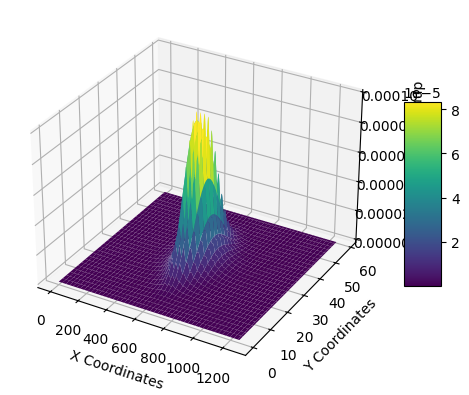

In [11]:
X = np.arange(NTOT)
Y = np.arange(M)

XM, YM = np.meshgrid(X,Y)
Z = np.abs(WV_ref_reshaped[0,0,:,:])**2

print(XM.shape, YM.shape, Z.shape)

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Plot a surface.
surf = ax.plot_surface(XM, YM, Z, cmap='viridis')

# Add a color bar which maps values to colors.
fig.colorbar(surf, shrink=0.5, aspect=5)

ax.set_xlabel('X Coordinates')
ax.set_ylabel('Y Coordinates')
ax.set_zlabel('wavefunction_e_spinup')

plt.show()

(60, 1260) (60, 1260) (60, 1260)


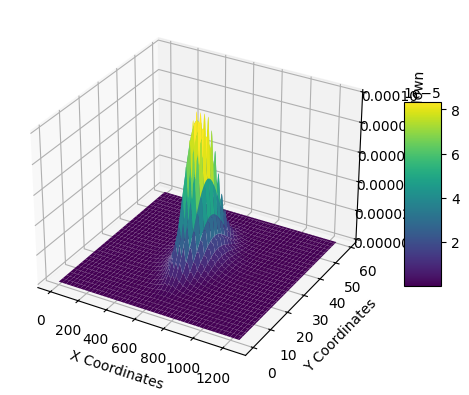

In [12]:
X = np.arange(NTOT)
Y = np.arange(M)

XM, YM = np.meshgrid(X,Y)
Z = np.abs(WV_ref_reshaped[0,1,:,:])**2

print(XM.shape, YM.shape, Z.shape)

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Plot a surface.
surf = ax.plot_surface(XM, YM, Z, cmap='viridis')

# Add a color bar which maps values to colors.
fig.colorbar(surf, shrink=0.5, aspect=5)

ax.set_xlabel('X Coordinates')
ax.set_ylabel('Y Coordinates')
ax.set_zlabel('wavefunction_e_spindown')

plt.show()

(60, 1260) (60, 1260) (60, 1260)


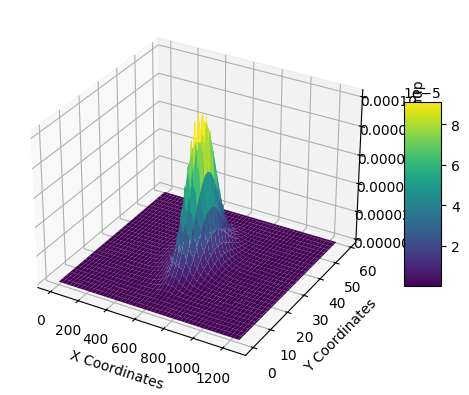

In [13]:
X = np.arange(NTOT)
Y = np.arange(M)

XM, YM = np.meshgrid(X,Y)
Z = np.abs(WV_ref_reshaped[1,0,:,:])**2

print(XM.shape, YM.shape, Z.shape)

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Plot a surface.
surf = ax.plot_surface(XM, YM, Z, cmap='viridis')

# Add a color bar which maps values to colors.
fig.colorbar(surf, shrink=0.5, aspect=5)

ax.set_xlabel('X Coordinates')
ax.set_ylabel('Y Coordinates')
ax.set_zlabel('wavefunction_h_spinup')

plt.show()

(60, 1260) (60, 1260) (60, 1260)


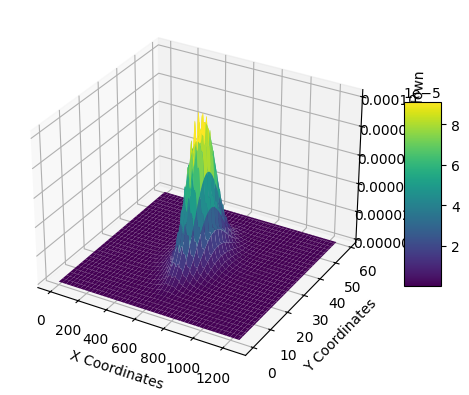

In [14]:
X = np.arange(NTOT)
Y = np.arange(M)

XM, YM = np.meshgrid(X,Y)
Z = np.abs(WV_ref_reshaped[1,1,:,:])**2

print(XM.shape, YM.shape, Z.shape)

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Plot a surface.
surf = ax.plot_surface(XM, YM, Z, cmap='viridis')

# Add a color bar which maps values to colors.
fig.colorbar(surf, shrink=0.5, aspect=5)

ax.set_xlabel('X Coordinates')
ax.set_ylabel('Y Coordinates')
ax.set_zlabel('wavefunction_h_spindown')

plt.show()